In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!unzip -q "/content/drive/MyDrive/Projet_Deep_Final/flicker8k.zip" -d "/content/dataset"
print("✅ Dataset décompressé et prêt à l'emploi !")

Mounted at /content/drive
unzip:  cannot find or open /content/drive/MyDrive/Projet_Deep_Final/flicker8k.zip, /content/drive/MyDrive/Projet_Deep_Final/flicker8k.zip.zip or /content/drive/MyDrive/Projet_Deep_Final/flicker8k.zip.ZIP.
✅ Dataset décompressé et prêt à l'emploi !


In [ ]:
import os
import random
import torch
import json
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from PIL import Image
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset, random_split
import matplotlib.pyplot as plt

In [ ]:
class EncoderCNN_Custom(nn.Module):
    def __init__(self, embed_size=512):  # Le vecteur final aura une taille de 512
        super(EncoderCNN_Custom, self).__init__()

        # nn.Sequential regroupe plusieurs couches. Les données passeront à la chaîne.
        self.cnn_layers = nn.Sequential(
            # Couche 1 : Prend l'image couleur (3 canaux : Rouge, Vert, Bleu), sort 32 filtres.
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), # Stabilise l'apprentissage (empêche les valeurs de trop s'éparpiller)
            nn.ReLU(),          # Fonction d'activation : met les valeurs négatives à zéro
            nn.MaxPool2d(2, 2), # Réduit la hauteur et la largeur de l'image par 2

            # Couches 2 à 5 : Le réseau devient de plus en plus profond.
            # Le nombre de filtres augmente (32 -> 64 -> 128 -> 256 -> 512).
            # Cela permet de comprendre des concepts de plus en plus complexes.
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),

            # Compression finale : Peu importe la taille de l'image à ce stade,
            # on la "rétrécit" à un carré de 1x1 (avec 512 canaux de profondeur)
            nn.AdaptiveAvgPool2d((1, 1))
        )

        # Couche de projection : on s'assure que la sortie est bien égale à 'embed_size'
        self.linear = nn.Linear(512, embed_size)
        # Dernière étape de normalisation sur le vecteur final de l'image
        self.bn = nn.BatchNorm1d(embed_size, momentum=0.01)

    # La méthode 'forward' définit le chemin que prend l'image (la variable 'images')
    def forward(self, images):
        features = self.cnn_layers(images)             # L'image traverse tout le CNN
        features = features.view(features.size(0), -1) # On "aplatit" le résultat en un vecteur 1D
        features = self.linear(features)               # Le vecteur passe dans la couche linéaire
        features = self.bn(features)                   # On normalise une dernière fois
        return features                                # On retourne le résumé de l'image (512 dimensions)

In [ ]:
class DecoderRNN(nn.Module):
    def __init__(self, embed_size, hidden_size, vocab_size, num_layers=2):
        super(DecoderRNN, self).__init__()

        # 1. La Projection : "Traduire" l'image pour le LSTM
        # Le CNN sort 512 valeurs. On les transforme pour qu'elles aient la même forme
        # que les mots (embed_size) et on applique GELU pour garder les nuances complexes.
        self.project_features = nn.Sequential(
            nn.Linear(512, embed_size),
            nn.GELU(),
            nn.BatchNorm1d(embed_size, momentum=0.01)
        )

        # 2. L'Embedding : Le dictionnaire du modèle
        # Transforme un index de mot (ex: le mot n°45) en un vecteur mathématique (embed_size)
        self.embed = nn.Embedding(vocab_size, embed_size)

        # 3. Le cerveau séquentiel : Le LSTM
        # Il prend en entrée les mots (et l'image au tout début) et s'en souvient
        # num_layers=2 signifie qu'on empile 2 LSTMs pour comprendre une grammaire plus complexe.
        # dropout=0.35 aide à éviter que le modèle n'apprenne les phrases "par cœur" (surapprentissage).
        self.lstm = nn.LSTM(embed_size, hidden_size, num_layers, batch_first=True, dropout=0.35)

        # 4. La sortie : Choisir le bon mot
        # Transforme l'état caché du LSTM en une probabilité pour chaque mot du vocabulaire
        self.linear = nn.Linear(hidden_size, vocab_size)

    def forward(self, features, captions):
        # features : le vecteur de l'image venant du CNN
        # captions : la vraie phrase (pour l'entraînement)

        # On "projette" l'image pour qu'elle soit compatible avec les mots
        features = self.project_features(features)

        # On enlève le dernier mot de la phrase (<end>) car le modèle doit le prédire, pas le lire.
        embeddings = self.embed(captions[:, :-1])

        # On "colle" l'image (features) au tout début de la phrase.
        # C'est le point de départ du LSTM.
        # unsqueeze(1) transforme la dimension pour qu'elle s'emboîte bien avec les mots.
        embeddings = torch.cat((features.unsqueeze(1), embeddings), dim=1)

        # Le LSTM lit l'image puis la phrase mot par mot
        lstm_out, _ = self.lstm(embeddings)

        # Pour chaque étape, on calcule les probabilités du prochain mot
        outputs = self.linear(lstm_out)

        return outputs

In [ ]:
def initialiser_poids(m):
    # Si la couche est une convolution (dans le CNN)
    if isinstance(m, nn.Conv2d):
        # Initialisation "Kaiming" : Parfaite quand on utilise l'activation ReLU juste après.
        # Ça empêche le signal de mourir dans les couches profondes.
        nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')

    # Si la couche est linéaire (Linear)
    elif isinstance(m, nn.Linear):
        # Initialisation "Xavier" : Équilibre la variance entre l'entrée et la sortie.
        nn.init.xavier_normal_(m.weight)
        if m.bias is not None:
            nn.init.constant_(m.bias, 0) # On met les biais à 0 au départ

    # Si la couche est un LSTM
    elif isinstance(m, nn.LSTM):
        for name, param in m.named_parameters():
            if 'weight_ih' in name or 'weight_hh' in name:
                # Initialisation Orthogonale : Crucial pour les RNN/LSTM !
                # Ça empêche les valeurs (gradients) d'exploser ou de disparaître
                # quand le modèle lit de très longues phrases.
                nn.init.orthogonal_(param)
            elif 'bias' in name:
                nn.init.constant_(param, 0) # Biais à 0

                # L'astuce magique : Le Forget Gate
                # Le biais est divisé en 4 portes. Le 2ème quart est la "Forget Gate" (porte d'oubli).
                # La mettre à 1.0 force le modèle à NE RIEN OUBLIER au tout début de l'entraînement.
                n = param.size(0)
                param.data[n//4:n//2].fill_(1.0)

In [ ]:
class Vocabulary:
    def __init__(self, freq_threshold=2):
        # freq_threshold=2 : On ignore les mots qui n'apparaissent qu'une seule fois.
        # Pourquoi ? Ça évite d'encombrer la mémoire du modèle avec des fautes de frappe
        # ou des mots beaucoup trop rares qui nuisent à l'apprentissage.

        # Les "Tokens" spéciaux de base (index 0 à 3)
        self.itos = {0: "<pad>", 1: "<start>", 2: "<end>", 3: "<unk>"}
        self.stoi = {"<pad>": 0, "<start>": 1, "<end>": 2, "<unk>": 3}

        # Explications pour ta présentation :
        # <pad> : "Padding". Sert à boucher les trous pour que toutes les phrases fassent la même taille.
        # <start> / <end> : Indiquent au modèle quand commencer et quand s'arrêter de parler.
        # <unk> : "Unknown". Remplace tous les mots inconnus ou trop rares.

        self.freq_threshold = freq_threshold

    def __len__(self):
        return len(self.itos)

    @staticmethod
    def tokenizer_eng(text):
        # Découpe une phrase en mots simples et les met en minuscules
        return text.lower().split()

    def build_vocabulary(self, sentence_list):
        # Construit le dictionnaire final
        frequencies = {}
        idx = 4 # On commence à 4 car les index 0, 1, 2, 3 sont déjà pris par les tokens spéciaux

        for sentence in sentence_list:
            for word in self.tokenizer_eng(sentence):
                frequencies[word] = frequencies.get(word, 0) + 1 # Compte les apparitions

                # Si le mot atteint le seuil (au moins 2 fois), on l'ajoute officiellement
                if frequencies[word] == self.freq_threshold:
                    self.stoi[word] = idx
                    self.itos[idx] = word
                    idx += 1

    def numericalize(self, text):
        # C'est la fonction qui traduit une vraie phrase en liste de nombres.
        # Exemple : "a dog runs" devient -> [1, 45, 12, 89, 2]
        tokenized_text = self.tokenizer_eng(text)

        # On encapsule toujours la phrase entre <start> et <end>
        return [self.stoi["<start>"]] + [
            self.stoi.get(word, self.stoi["<unk>"]) for word in tokenized_text
        ] + [self.stoi["<end>"]]

In [ ]:
class FlickrDataset(Dataset):
    # Cette classe explique à PyTorch comment lire UNE image et SA légende associée
    def __init__(self, root_dir, captions_file, transform=None, freq_threshold=2):
        self.root_dir = root_dir # Le dossier contenant les images

        # Ouverture du fichier JSON contenant toutes les légendes
        with open(captions_file, 'r') as f:
            self.captions_dict = json.load(f)

        self.transform = transform # Les modifications d'images (redimensionnement, etc.)

        # On crée une grande liste plate de tous les couples (nom_image, phrase)
        self.imgs_captions = []
        for img_id, captions in self.captions_dict.items():
            for cap in captions:
                self.imgs_captions.append((img_id, cap))

        # On initialise et on remplit le vocabulaire (la classe d'au-dessus)
        self.vocab = Vocabulary(freq_threshold)
        self.vocab.build_vocabulary([cap for _, cap in self.imgs_captions])

    def __len__(self):
        return len(self.imgs_captions) # Le nombre total de couples image/phrase

    def __getitem__(self, index):
        # Quand le modèle demande la donnée n°[index], cette fonction s'active.
        caption, img_id = self.imgs_captions[index][1], self.imgs_captions[index][0]

        # 1. Ouvre l'image et s'assure qu'elle est en couleurs RGB
        img = Image.open(os.path.join(self.root_dir, img_id)).convert("RGB")

        # 2. Applique les transformations visuelles
        if self.transform is not None:
            img = self.transform(img)

        # 3. Convertit la phrase en liste de nombres (via la fonction numericalize)
        numericalized_caption = [self.vocab.stoi["<start>"]] + \
                                [self.vocab.stoi.get(word, self.vocab.stoi["<unk>"]) for word in self.vocab.tokenizer_eng(caption)] + \
                                [self.vocab.stoi["<end>"]]

        # Retourne l'image prête et la phrase convertie en "Tenseur" (matrice PyTorch)
        return img, torch.tensor(numericalized_caption)


# La fonction d'alignement (Extrêmement importante pour ta soutenance !)
class aligner_phrases:
    def __init__(self, pad_idx):
        self.pad_idx = pad_idx # L'index du token <pad> (qui est le 0)

    # Pourquoi cette fonction ?
    # Le modèle s'entraîne en lisant plusieurs images à la fois (un "Batch" de 32 ou 64 images).
    # Le problème, c'est que dans un lot de 32 phrases, certaines sont courtes et d'autres longues.
    # PyTorch déteste ça, il a besoin de matrices parfaitement carrées/rectangulaires.
    def __call__(self, batch):
        # Récupère toutes les images du lot
        imgs = [item[0].unsqueeze(0) for item in batch]
        imgs = torch.cat(imgs, dim=0)

        # Récupère toutes les phrases du lot
        targets = [item[1] for item in batch]

        # La magie opère ici : pad_sequence va regarder la phrase la plus longue du lot,
        # et va ajouter des zéros (<pad>) à la fin de toutes les autres phrases plus courtes
        # pour que tout le monde ait la même taille.
        targets = pad_sequence(targets, batch_first=True, padding_value=self.pad_idx)

        return imgs, targets

In [ ]:
def forward_teacher_forcing(encoder, decoder, images, captions, vocab, teacher_forcing_ratio=0.5):
    # 1. On passe l'image dans l'encodeur pour obtenir son vecteur de 512 dimensions
    features = encoder(images)

    # 2. On prépare la taille de ce qu'on va générer (la longueur maximale de la vraie phrase)
    batch_size = features.size(0)
    max_len = captions.size(1)
    vocab_size = len(vocab)

    # On crée un tableau vide (rempli de zéros) pour stocker les prédictions du modèle
    outputs = torch.zeros(batch_size, max_len, vocab_size).to(images.device)

    # 3. On projette l'image pour l'adapter au décodeur (LSTM)
    features = decoder.project_features(features)

    # L'état caché du LSTM s'initialise avec l'image (c'est le point de départ de la pensée du modèle)
    hidden = None
    inputs = features.unsqueeze(1)

    # 4. La boucle de génération mot par mot
    for t in range(1, max_len): # On boucle sur la longueur de la phrase
        # Le LSTM regarde l'entrée (l'image au début, puis les mots) et génère une sortie
        lstm_out, hidden = decoder.lstm(inputs, hidden)

        # On calcule les probabilités pour le mot actuel
        output = decoder.linear(lstm_out.squeeze(1))
        outputs[:, t, :] = output # On sauvegarde la prédiction

        # C'est ici qu'intervient le Teacher Forcing !
        # On tire un nombre au hasard entre 0 et 1.
        # S'il est plus petit que notre ratio (ex: 1.0 au début), on utilise le vrai mot (Teacher Forcing).
        # Sinon, on utilise la meilleure prédiction que le modèle vient de faire.
        teacher_force = random.random() < teacher_forcing_ratio

        # argmax(1) prend le mot qui a la plus forte probabilité selon le modèle
        top1 = output.argmax(1)

        # L'entrée pour le prochain tour de boucle : le vrai mot OU le mot prédit ?
        next_input = captions[:, t] if teacher_force else top1

        # On transforme ce mot en vecteur mathématique (embedding) pour le prochain tour
        inputs = decoder.embed(next_input).unsqueeze(1)

    return outputs

In [ ]:
# ============================================================
# CELL 9 — CONFIGURATION ET ENTRAÎNEMENT PRINCIPAL
# ============================================================

# --- CHEMINS ---
dossier_images      = "/content/dataset/flicker8k/Images"
fichier_captions    = "/content/dataset/flicker8k/captions.txt"
dossier_sauvegarde  = "/content/drive/MyDrive/Projet_Deep_Final"

# --- DEVICE (Matériel) ---
# POURQUOI ? Les modèles de Deep Learning font des millions de multiplications matricielles.
# Un CPU classique est trop lent. On bascule sur la carte graphique (GPU/CUDA) pour diviser
# le temps d'entraînement par 10 ou 20.
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"🚀 GPU : {torch.cuda.get_device_name(0)}")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("🚀 Apple Silicon MPS")
else:
    device = torch.device("cpu")
    print("🐌 CPU uniquement")

if device.type == 'cuda':
    torch.backends.cudnn.benchmark = True # POURQUOI ? Demande à PyTorch d'optimiser automatiquement les algorithmes de convolution selon la taille exacte de nos images.

# --- VOCABULAIRE ---
print("📖 Construction du vocabulaire...")
vocab = Vocabulary()
phrases_flickr = []

with open(fichier_captions, 'r', encoding='utf-8') as f:
    for ligne in f.readlines()[1:]:
        parties = ligne.strip().split(',')
        if len(parties) >= 2:
            phrases_flickr.append(",".join(parties[1:]))

# POURQUOI freq_seuil=2 ? On retire les mots qui n'apparaissent qu'une seule fois dans tout le dataset (les hapax).
# Cela supprime le "bruit" (fautes de frappe, mots trop rares) et évite au modèle de s'encombrer la mémoire inutilement.
vocab.build_vocabulary(phrases_flickr, freq_seuil=2)
print(f"✅ Vocabulaire : {vocab.idx} mots (hapax exclus)")

# --- TRANSFORMATIONS (Data Augmentation) ---
# POURQUOI ? C'est notre meilleure arme contre l'overfitting. Si le modèle voit toujours la même image exacte,
# il l'apprend par cœur. En la rognant, la retournant et changeant ses couleurs, on crée virtuellement
# des milliers de nouvelles images. Le réseau est forcé de comprendre le "concept" (ex: un chien) plutôt que les pixels exacts.
transformations_train = transforms.Compose([
    transforms.Resize((236, 236)),
    transforms.RandomCrop((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    # Normalisation mathématique standardisée sur les couleurs (basée sur le dataset ImageNet)
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# POURQUOI pas de RandomCrop ou de Flip ici ? La validation sert d'examen final.
# On ne modifie pas les images d'examen, on veut voir comment le modèle réagit sur de vraies photos intactes.
transformations_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# --- DATASET ET DATALOADERS ---
dataset_train_complet = FlickrDataset(dossier_images, fichier_captions, vocab, transformations_train)
dataset_val_complet   = FlickrDataset(dossier_images, fichier_captions, vocab, transformations_val)

# Séparation classique : 80% pour l'entraînement, 20% pour vérifier que le modèle ne triche pas (validation)
taille_train = int(0.8 * len(dataset_train_complet))
taille_val   = len(dataset_train_complet) - taille_train

gen_train = torch.Generator().manual_seed(42) # manual_seed permet de toujours avoir la même séparation à chaque exécution
gen_val   = torch.Generator().manual_seed(42)

train_dataset, _ = random_split(dataset_train_complet, [taille_train, taille_val], generator=gen_train)
_, val_dataset   = random_split(dataset_val_complet,   [taille_train, taille_val], generator=gen_val)

# POURQUOI num_workers=2 et pin_memory=True ?
# Le GPU calcule très vite. Si le CPU prépare les images trop lentement, le GPU attend à ne rien faire (bottleneck).
# num_workers utilise plusieurs cœurs du processeur pour charger les images en parallèle.
# pin_memory accélère le transfert des images de la RAM vers la carte graphique.
train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True,
    collate_fn=aligner_phrases,
    num_workers=2, pin_memory=True, persistent_workers=True
)
val_loader = DataLoader(
    val_dataset, batch_size=128, shuffle=False,
    collate_fn=aligner_phrases,
    num_workers=2, pin_memory=True, persistent_workers=True
)

# --- MODÈLES ---
taille_embedding = 512
taille_cachee    = 512

encoder = EncoderCNN_Custom(embed_size=taille_embedding).to(device)
decoder = DecoderRNN(
    embed_size=taille_embedding,
    hidden_size=taille_cachee,
    vocab_size=vocab.idx,
    num_layers=2
).to(device)

encoder.apply(initialiser_poids)
decoder.apply(initialiser_poids)
print("✅ Poids initialisés (Kaiming He + Orthogonal LSTM + Forget gate=1)")

# POURQUOI torch.compile ? C'est une technologie de PyTorch 2.0 qui analyse ton code
# et le transforme en instructions machine hyper-optimisées. Ça accélère considérablement l'entraînement de l'encodeur.
encoder = torch.compile(encoder)
print("✅ Encodeur compilé avec torch.compile()")

# --- REPRISE D'ENTRAÎNEMENT ---
# Sauvegarde et chargement automatique pour ne pas tout perdre si Colab plante.
chemin_encodeur       = f"{dossier_sauvegarde}/encodeur_meilleur.pth"
chemin_decodeur       = f"{dossier_sauvegarde}/decodeur_meilleur.pth"
chemin_meilleure_loss = f"{dossier_sauvegarde}/meilleure_loss.txt"
chemin_historique     = f"{dossier_sauvegarde}/historique_losses.json"

if os.path.exists(chemin_meilleure_loss):
    with open(chemin_meilleure_loss, 'r') as f:
        meilleure_loss_val = float(f.read())
    print(f"📊 Meilleure val loss connue : {meilleure_loss_val:.4f}")
else:
    meilleure_loss_val = float('inf')

if os.path.exists(chemin_encodeur) and os.path.exists(chemin_decodeur):
    print("🔄 Reprise de l'entraînement depuis les poids sauvegardés...")
    encoder.load_state_dict(torch.load(chemin_encodeur, map_location=device), strict=False)
    decoder.load_state_dict(torch.load(chemin_decodeur, map_location=device), strict=False)
    print("✅ Poids rechargés !")
else:
    print("🌱 Nouvel entraînement de zéro.")

# --- LOSS (Fonction d'erreur) ---
# POURQUOI ignore_index=0 ? Le 0 correspond au token <pad> (le remplissage). On ne veut pas que le modèle soit puni ou récompensé pour avoir prédit du vide.
# POURQUOI label_smoothing=0.1 ? Au lieu de dire au modèle "La vraie réponse est Chien à 100%", on lui dit "C'est Chien à 90%, et répartis les 10% restants sur le reste du dictionnaire".
# Ça l'empêche d'avoir des certitudes trop fortes, ce qui limite énormément le surapprentissage.
criterion = nn.CrossEntropyLoss(ignore_index=0, label_smoothing=0.1)

# --- OPTIMISEUR ---
# POURQUOI des vitesses d'apprentissage (lr) différentes ?
# L'encodeur (CNN) détecte des formes de base, il n'a pas besoin d'être bouleversé, on lui met un taux lent (1e-4).
# Le décodeur (LSTM) part de zéro pour générer du langage, il doit apprendre plus vite (3e-4).
# POURQUOI weight_decay=1e-4 ? C'est une pénalité mathématique (Régularisation L2). Elle empêche les poids du réseau de devenir des nombres trop grands. Ça force le modèle à rester "simple" et généraliste.
optimizer = optim.Adam([
    {'params': encoder.parameters(), 'lr': 1e-4, 'weight_decay': 1e-4},
    {'params': decoder.parameters(), 'lr': 3e-4, 'weight_decay': 1e-4}
])

# --- SCHEDULER (Planificateur de taux d'apprentissage) ---
# POURQUOI ReduceLROnPlateau ? Ce planificateur surveille la perte (loss). S'il voit que le modèle arrête de s'améliorer
# pendant 3 époques de suite (patience=3), il divise la vitesse d'apprentissage par 2 (factor=0.5).
# C'est comme le golf : au début on frappe fort (grand taux), mais près du trou on fait de petits coups très précis pour ne pas le rater.
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

# --- MIXED PRECISION (Précision mixte) ---
# POURQUOI ? Traditionnellement, l'IA utilise des nombres à virgule très précis (float32).
# Le Mixed Precision utilise des nombres moins précis (float16) là où ce n'est pas grave,
# ce qui divise par deux la consommation de mémoire (RAM de la carte graphique) et accélère massivement les calculs, sans perdre en performance.
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

# --- HISTORIQUES ---
historique_train_epochs = []
historique_train_loss   = []
historique_val_epochs   = []
historique_val_loss     = []
compteur_global_lots    = 0
loss_cumulee_100_lots   = 0

🚀 GPU : Tesla T4
✅ cuDNN benchmark activé
📖 Construction du vocabulaire...
✅ Vocabulaire : 5320 mots (hapax exclus)
✅ Poids initialisés (Kaiming He + Orthogonal LSTM + Forget gate=1)
✅ Encodeur compilé avec torch.compile()
🔄 Reprise de l'entraînement depuis les poids sauvegardés...
✅ Poids rechargés !


In [ ]:
#Sécurité
secu = True

if secu:
    # Tu peux utiliser Exception, ou des erreurs plus précises comme RuntimeError ou ValueError
    raise RuntimeError("Garde-fou déclenché : exécution bloquée car secu est True !")

# Le code qui suit ne s'exécutera pas si l'erreur a été déclenchée au-dessus
print("Le script continue normalement...")


  # --- BOUCLE D'ENTRAÎNEMENT ---
nombre_epoques = 20

print(f"\n🔥 Début de l'entraînement pour {nombre_epoques} époques...")

for epoque in range(nombre_epoques):
    encoder.train()
    decoder.train()

    teacher_forcing_ratio = 1

    for i, (images, captions) in enumerate(train_loader):
        images  = images.to(device, non_blocking=True)
        captions = captions.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)  # ✅ plus rapide que zero_grad()

        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            features             = encoder(images)
            predictions          = forward_teacher_forcing(
                decoder, features, captions, vocab.idx, teacher_forcing_ratio
            )
            predictions_aplaties = predictions.reshape(-1, vocab.idx)
            targets_aplatis      = captions[:, 1:].reshape(-1)
            loss                 = criterion(predictions_aplaties, targets_aplatis)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        all_params = list(encoder.parameters()) + list(decoder.parameters())
        torch.nn.utils.clip_grad_norm_(all_params, max_norm=5.0)
        scaler.step(optimizer)
        scaler.update()

        loss_cumulee_100_lots += loss.item()
        compteur_global_lots  += 1

        if compteur_global_lots % 100 == 0:
            loss_moyenne  = loss_cumulee_100_lots / 100
            epoque_exacte = compteur_global_lots / len(train_loader)
            historique_train_epochs.append(epoque_exacte)
            historique_train_loss.append(loss_moyenne)
            print(f"   [Train] Époque {epoque+1}/{nombre_epoques} | "
                  f"Lot {i}/{len(train_loader)} | "
                  f"Loss: {loss_moyenne:.4f} | "
                  f"TF ratio: {teacher_forcing_ratio:.2f}")
            loss_cumulee_100_lots = 0

    # --- VALIDATION ---
    encoder.eval()
    decoder.eval()
    loss_val_totale = 0

    with torch.no_grad():
        for images, captions in val_loader:
            images   = images.to(device, non_blocking=True)
            captions = captions.to(device, non_blocking=True)

            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                features             = encoder(images)
                predictions          = forward_teacher_forcing(
                    decoder, features, captions, vocab.idx, ratio=1.0
                )
                predictions_aplaties = predictions.reshape(-1, vocab.idx)
                targets_aplatis      = captions[:, 1:].reshape(-1)
                loss_val             = criterion(predictions_aplaties, targets_aplatis)

            loss_val_totale += loss_val.item()

    # ✅ FIX : calcul de la moyenne AVANT de l'utiliser
    loss_val_moyenne = loss_val_totale / len(val_loader)
    historique_val_epochs.append(epoque + 1)
    historique_val_loss.append(loss_val_moyenne)

    lr_actuel = optimizer.param_groups[0]['lr']
    print(f"👉 FIN ÉPOQUE {epoque+1} | Val Loss: {loss_val_moyenne:.4f} | "
          f"TF ratio: {teacher_forcing_ratio:.2f} | LR: {lr_actuel:.2e}")

    scheduler.step(loss_val_moyenne)

    if loss_val_moyenne < meilleure_loss_val:
        meilleure_loss_val = loss_val_moyenne
        print("🌟 Nouveau record ! Sauvegarde des poids...")
        encoder_a_sauvegarder = encoder._orig_mod if hasattr(encoder, '_orig_mod') else encoder
        torch.save(encoder_a_sauvegarder.state_dict(), chemin_encodeur)
        torch.save(decoder.state_dict(), chemin_decodeur)
        with open(chemin_meilleure_loss, 'w') as f:
            f.write(str(meilleure_loss_val))

    print("-" * 60)

# --- COURBES ---
plt.figure(figsize=(12, 6))
plt.plot(historique_train_epochs, historique_train_loss, label='Train Loss', linewidth=2)
plt.plot(historique_val_epochs,   historique_val_loss,   label='Val Loss',   linewidth=2)
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title("Courbes d'apprentissage")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- SAUVEGARDE HISTORIQUE ---
if os.path.exists(chemin_historique):
    with open(chemin_historique, 'r') as f:
        historique_global = json.load(f)
else:
    historique_global = {
        "train_epochs": [],
        "train_loss":   [],
        "val_epochs":   [],
        "val_loss":     []
    }

offset_epochs = historique_global["val_epochs"][-1] if historique_global["val_epochs"] else 0

historique_global["train_epochs"] += [e + offset_epochs for e in historique_train_epochs]
historique_global["train_loss"]   += historique_train_loss
historique_global["val_epochs"]   += [e + offset_epochs for e in historique_val_epochs]
historique_global["val_loss"]     += historique_val_loss

with open(chemin_historique, 'w') as f:
    json.dump(historique_global, f)

print(f"✅ Historique sauvegardé ({len(historique_global['val_epochs'])} époques au total)")

RuntimeError: Garde-fou déclenché : exécution bloquée car secu est True !

⚙️ Chargement des modèles...
✅ Poids rechargés avec succès !
📸 L'IA analyse ton image...


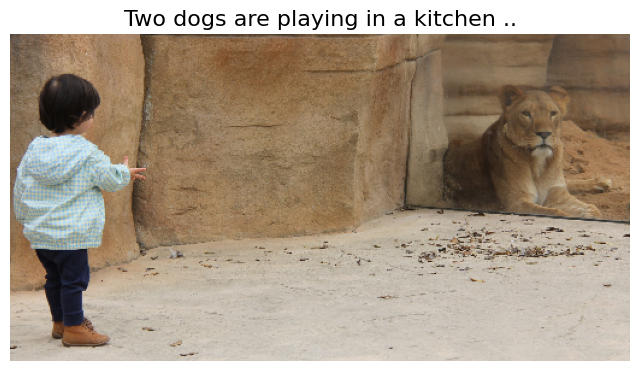


🤖 L'IA a dit : "Two dogs are playing in a kitchen .."


In [ ]:
# ============================================================
# CELL 11 — INFÉRENCE / GÉNÉRATION DE LÉGENDES
# FIX : EncoderCNN_Custom(embed_size=512) — cohérent avec l'entraînement
# FIX : DecoderRNN avec embed_size=512
# ============================================================
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

CHEMIN_IMAGE_TEST       = '/content/drive/MyDrive/Projet_Deep_Final/photo_test/imagetest.png'
CHEMIN_POIDS_ENCODEUR   = '/content/drive/MyDrive/Projet_Deep_Final/encodeur_meilleur.pth'
CHEMIN_POIDS_DECODEUR   = '/content/drive/MyDrive/Projet_Deep_Final/decodeur_meilleur.pth'


def decrire_image(chemin_image, encodeur, decodeur, vocabulaire, device, longueur_max=20):
    encodeur.eval()
    decodeur.eval()

    transformations = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    image_pil    = Image.open(chemin_image).convert("RGB")
    image_tensor = transformations(image_pil).unsqueeze(0).to(device)
    mots_generes = []

    with torch.no_grad():
        features = encodeur(image_tensor)

        # ✅ project_features est maintenant un Sequential (Linear + GELU)
        inputs       = decodeur.project_features(features).unsqueeze(1)
        memoire_lstm = None

        for _ in range(longueur_max):
            lstm_out, memoire_lstm = decodeur.lstm(inputs, memoire_lstm)
            outputs        = decodeur.linear(lstm_out.squeeze(1))
            mot_choisi_idx = outputs.argmax(1)

            if mot_choisi_idx.item() == vocabulaire.word2idx["<end>"]:
                break

            mots_generes.append(mot_choisi_idx.item())
            inputs = decodeur.embed(mot_choisi_idx).unsqueeze(1)

    phrase_finale = [
        vocabulaire.idx2word[num]
        for num in mots_generes
        if vocabulaire.idx2word[num] not in ["<start>", "<pad>", "<unk>"]
    ]

    phrase_texte = " ".join(phrase_finale)

    plt.figure(figsize=(8, 8))
    plt.imshow(image_pil)
    plt.axis('off')
    plt.title(phrase_texte.capitalize() + ".", fontsize=16)
    plt.show()

    return phrase_texte


# --- EXÉCUTION ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("⚙️ Chargement des modèles...")

# ✅ FIX CRITIQUE : embed_size=512 — identique à l'entraînement
encoder_test = EncoderCNN_Custom(embed_size=512).to(device)
decoder_test = DecoderRNN(
    embed_size=512,
    hidden_size=512,
    vocab_size=vocab.idx,
    num_layers=2
).to(device)

state_dict_encoder = torch.load(CHEMIN_POIDS_ENCODEUR, map_location=device)
state_dict_encoder = {k.replace("_orig_mod.", ""): v for k, v in state_dict_encoder.items()}
encoder_test.load_state_dict(state_dict_encoder)

state_dict_decoder = torch.load(CHEMIN_POIDS_DECODEUR, map_location=device)
state_dict_decoder = {k.replace("_orig_mod.", ""): v for k, v in state_dict_decoder.items()}
decoder_test.load_state_dict(state_dict_decoder)
print("✅ Poids rechargés avec succès !")

print("📸 L'IA analyse ton image...")
legende = decrire_image(CHEMIN_IMAGE_TEST, encoder_test, decoder_test, vocab, device)
print(f'\n🤖 L\'IA a dit : "{legende.capitalize()}."')

✅ Modèles chargés.

──────────────────────────────────────────────────────────────────────
#    Image                          Légende générée             Loss
──────────────────────────────────────────────────────────────────────
1    1466307489_cb8a74de09.jpg      a group of people are r.. 3.1407
2    3029463004_c2d2c8f404.jpg      a man is surfing on a w.. 2.2614
3    2438085746_588dce8724.jpg      a black and white dog j.. 1.9546
4    3522025527_c10e6ebd26.jpg      a man is standing on a .. 3.6358
5    3273969811_42e9fa8f63.jpg      a white bird flies over.. 2.0178
6    2224450291_4c133fabe8.jpg      a man in a green shirt .. 3.6417
7    3497237366_366997495d.jpg      a man in a green shirt .. 3.0088
8    69710415_5c2bfb1058.jpg        a group of people are s.. 2.6361
9    3613175012_bcd063e7c9.jpg      a group of people are w.. 3.2339
10   86412576_c53392ef80.jpg        two young boys are sitt.. 4.0451
11   1289142574_2bd6a082dd.jpg      a boy is sitting on a p.. 3.1008
12   36561

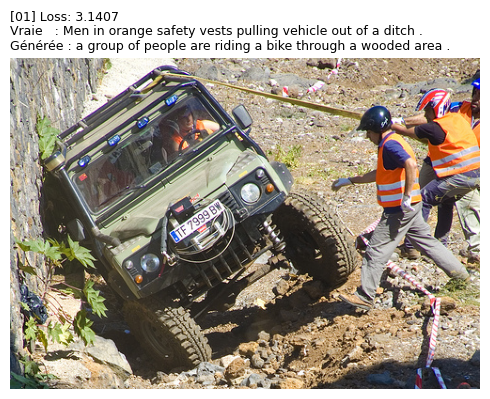


[02] 3029463004_c2d2c8f404.jpg
  Vraie   : A surfer rides the waves .
  Générée : a man is surfing on a wave .
  Loss    : 2.2614


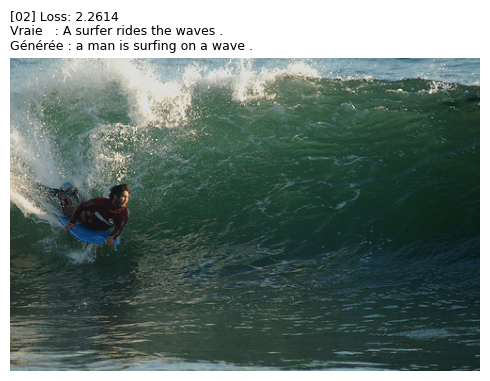


[03] 2438085746_588dce8724.jpg
  Vraie   : A black and white dog jumps to catch the green Frisbee .
  Générée : a black and white dog jumps to catch a frisbee .
  Loss    : 1.9546


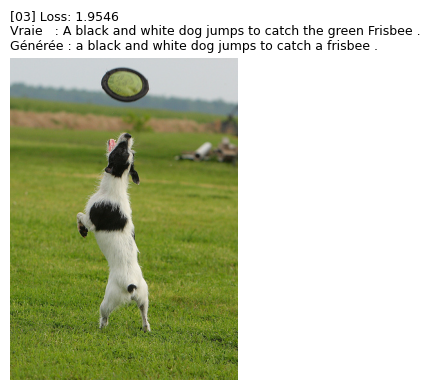


[04] 3522025527_c10e6ebd26.jpg
  Vraie   : A plane and a helicopter in the sky . houses seen underneat and people sitting .
  Générée : a man is standing on a hill overlooking a lake .
  Loss    : 3.6358


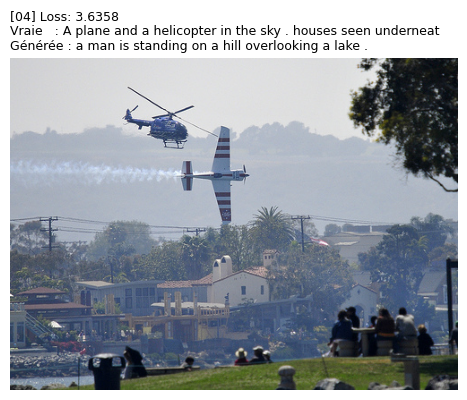


[05] 3273969811_42e9fa8f63.jpg
  Vraie   : A large white bird flies out of the water .
  Générée : a white bird flies over water .
  Loss    : 2.0178


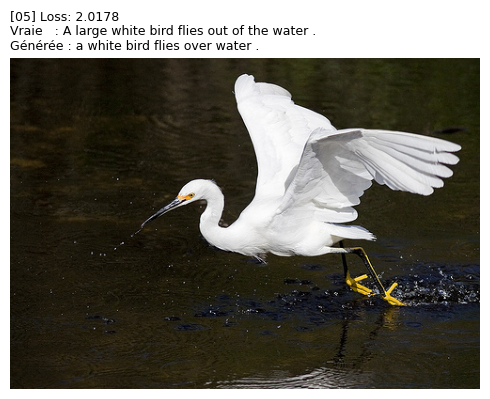


[06] 2224450291_4c133fabe8.jpg
  Vraie   : A man in a tropical enviorment holding a camera to his face .
  Générée : a man in a green shirt is standing next to a girl in a green shirt and a green shirt
  Loss    : 3.6417


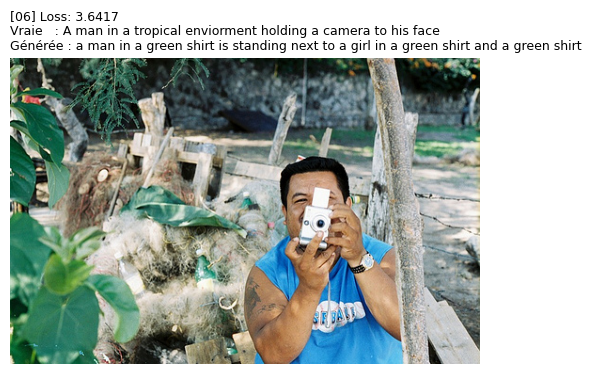


[07] 3497237366_366997495d.jpg
  Vraie   : A basketball player attempts a layup in a gymnasium .
  Générée : a man in a green shirt is doing a trick on a skateboard .
  Loss    : 3.0088


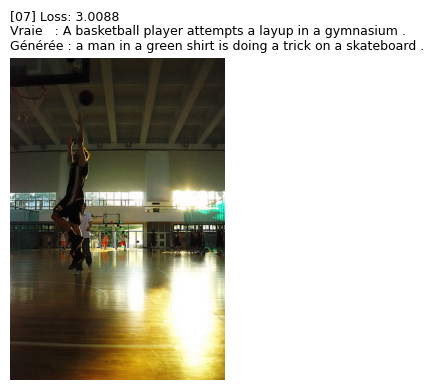


[08] 69710415_5c2bfb1058.jpg
  Vraie   : Three scouts are on top of a cliff overlooking the ocean .
  Générée : a group of people are standing on a rock overlooking a valley .
  Loss    : 2.6361


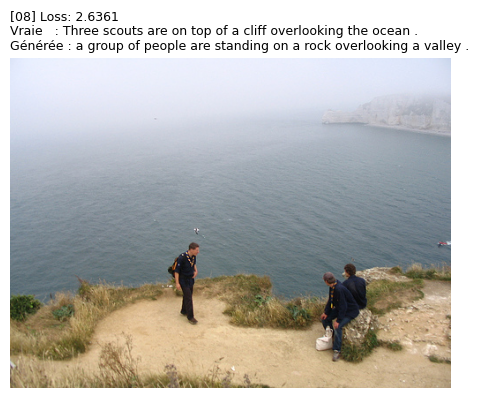


[09] 3613175012_bcd063e7c9.jpg
  Vraie   : "Four young people walk down a sunny street , one pushing a shopping cart"
  Générée : a group of people are walking down a street .
  Loss    : 3.2339


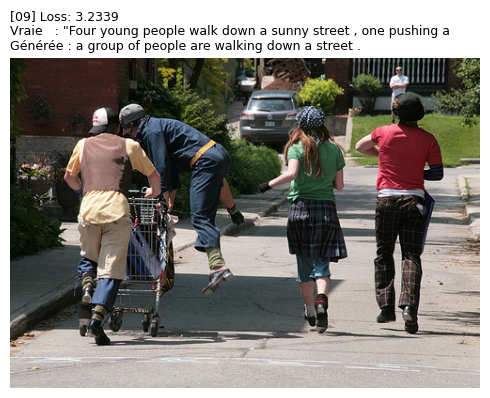


[10] 86412576_c53392ef80.jpg
  Vraie   : A group of people are walking while holding numerous baskets and rugs .
  Générée : two young boys are sitting on a bench .
  Loss    : 4.0451


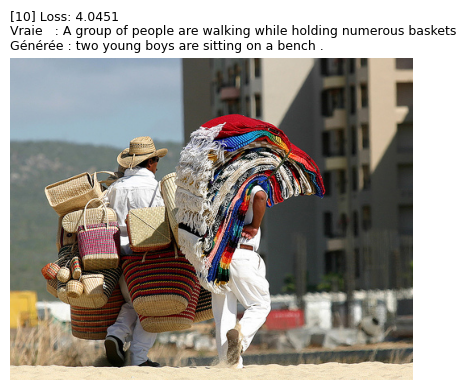


[11] 1289142574_2bd6a082dd.jpg
  Vraie   : A boy jumps from one picnic table to another .
  Générée : a boy is sitting on a playground .
  Loss    : 3.1008


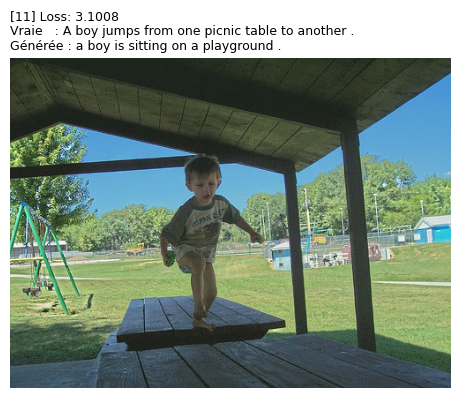


[12] 3656104088_a0d1642fa9.jpg
  Vraie   : A pelican in mid-flight above a group of pelicans .
  Générée : a group of dogs are running on a grassy field .
  Loss    : 3.7402


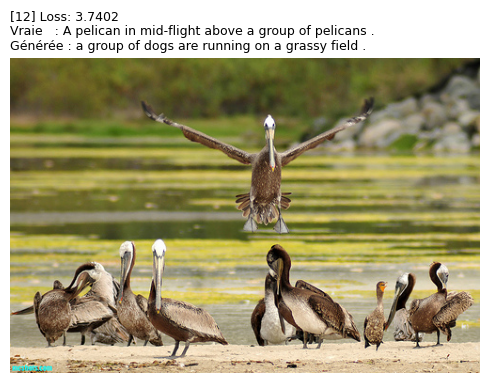


[13] 3441531010_8eebbb507e.jpg
  Vraie   : A dog runs through shallow water .
  Générée : a dog is jumping through the water .
  Loss    : 2.2286


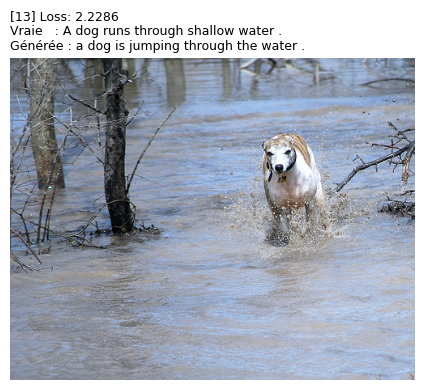


[14] 508432819_3d055f395d.jpg
  Vraie   : Monster Truck rides through dirt field
  Générée : a black dog is running through a field of leaves .
  Loss    : 4.7687


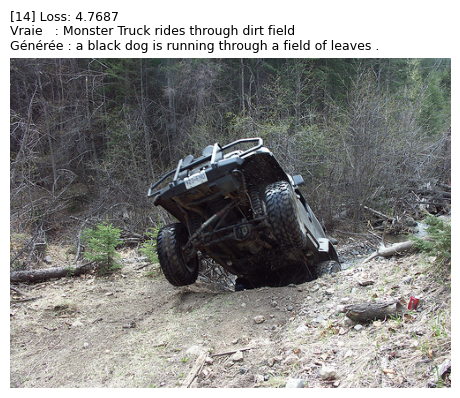


[15] 3281611946_f42deed2e1.jpg
  Vraie   : Two men have fun drinking
  Générée : two young boys are playing with a blue and blue ball .
  Loss    : 5.1404


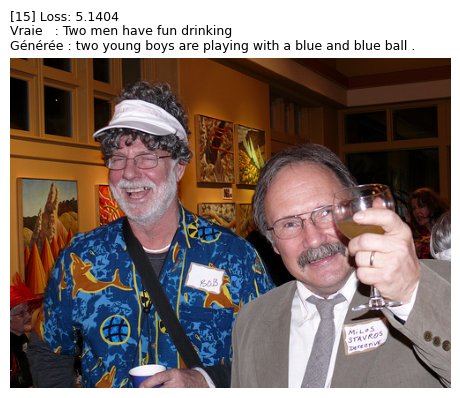


[16] 405051459_3b3a3ba5b3.jpg
  Vraie   : A woman is walking with a red bag .
  Générée : a man in a red shirt and a black hat is walking on a sidewalk .
  Loss    : 2.7862


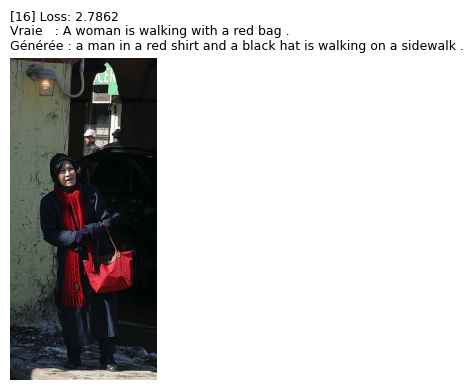


[17] 3446191973_1db572ed8a.jpg
  Vraie   : People stand on the edge of a waterway striped with red and white where a large 
  Générée : a group of people stand on a sidewalk and look at the camera .
  Loss    : 4.7592


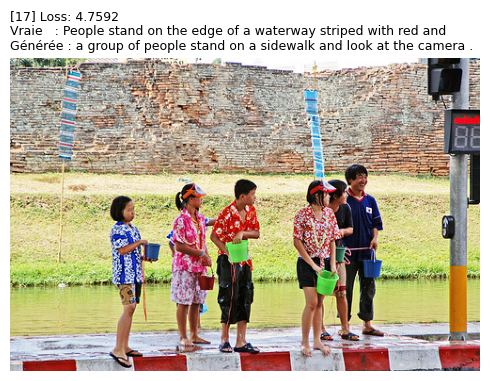


[18] 3342487512_fd33971dea.jpg
  Vraie   : A snowboarder doing a jump on a K2 snowboard .
  Générée : a person is performing a trick on a skateboard in a skate park .
  Loss    : 2.8019


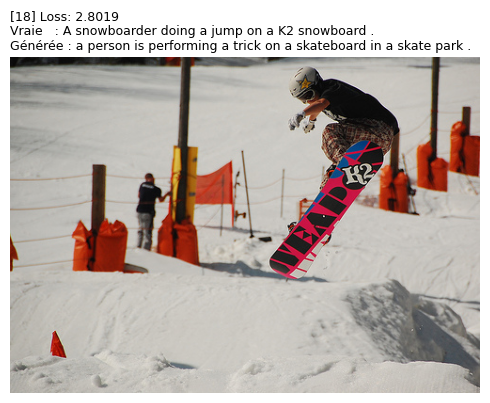


[19] 2573141440_28a762d537.jpg
  Vraie   : "A little girl in a yellow outfit sitting in a blue , yellow and red swing ."
  Générée : a young boy in a blue shirt is riding a blue swing .
  Loss    : 3.1945


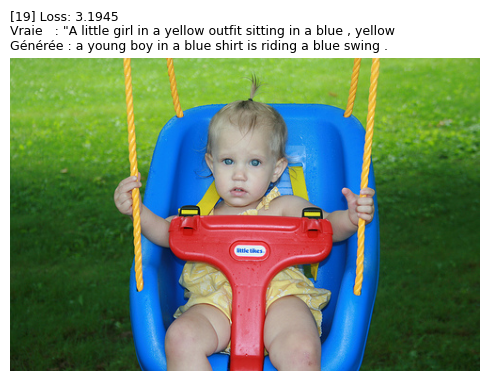


[20] 1858963639_4588cd4be9.jpg
  Vraie   : A woman wearing a red helmet is holding a rope and smiling .
  Générée : a woman in a red shirt is standing in a tree .
  Loss    : 2.4317


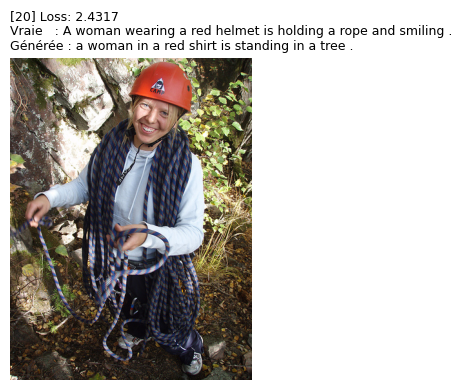

──────────────────────────────────────────────────────────────────────

💡 INTERPRÉTATION DE LA LOSS
────────────────────────────────────────
  Loss 3.2264 → 🟠 Début d'apprentissage — quelques mots corrects


In [ ]:
# ============================================================
# CELL 12 — TEST : LOSS MOYENNE SUR 20 IMAGES
# ============================================================
import torch
import torch.nn as nn
from torchvision import transforms
from PIL import Image
import os
import random

# --- CONFIGURATION ---
DOSSIER_IMAGES      = "/content/dataset/flicker8k/Images"
FICHIER_CAPTIONS    = "/content/dataset/flicker8k/captions.txt"
CHEMIN_ENCODEUR     = "/content/drive/MyDrive/Projet_Deep_Final/encodeur_meilleur.pth"
CHEMIN_DECODEUR     = "/content/drive/MyDrive/Projet_Deep_Final/decodeur_meilleur.pth"
NB_IMAGES_TEST      = 20
longueur_max=20

# --- CHARGEMENT DES MODÈLES ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

encoder_test = EncoderCNN_Custom(embed_size=512).to(device)
decoder_test = DecoderRNN(
    embed_size=512,
    hidden_size=512,
    vocab_size=vocab.idx,
    num_layers=2
).to(device)

state_dict_encoder = torch.load(CHEMIN_ENCODEUR, map_location=device)
state_dict_encoder = {k.replace("_orig_mod.", ""): v for k, v in state_dict_encoder.items()}
encoder_test.load_state_dict(state_dict_encoder)

state_dict_decoder = torch.load(CHEMIN_DECODEUR, map_location=device)
state_dict_decoder = {k.replace("_orig_mod.", ""): v for k, v in state_dict_decoder.items()}
decoder_test.load_state_dict(state_dict_decoder)
encoder_test.eval()
decoder_test.eval()
print("✅ Modèles chargés.")

# --- LECTURE DES PAIRES IMAGE/CAPTION ---
paires = []
with open(FICHIER_CAPTIONS, 'r', encoding='utf-8') as f:
    for ligne in f.readlines()[1:]:
        parties = ligne.strip().split(',')
        if len(parties) >= 2:
            nom_image = parties[0]
            phrase    = ",".join(parties[1:])
            paires.append((nom_image, phrase))

# On tire 20 paires au hasard (seed fixe pour reproductibilité)
random.seed(43)
paires_test = random.sample(paires, NB_IMAGES_TEST)

# --- TRANSFORMATIONS ---
transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# --- CALCUL DE LA LOSS ---
criterion = nn.CrossEntropyLoss(ignore_index=0, label_smoothing=0.1)

resultats   = []
loss_totale = 0.0

print(f"\n{'─'*70}")
print(f"{'#':<4} {'Image':<30} {'Légende générée':<25} {'Loss':>6}")
print(f"{'─'*70}")

with torch.no_grad():
    for i, (nom_image, phrase_vraie) in enumerate(paires_test):

        # 1. Charger et transformer l'image
        chemin = os.path.join(DOSSIER_IMAGES, nom_image)
        image  = Image.open(chemin).convert("RGB")
        img_t  = transform_test(image).unsqueeze(0).to(device)

        # 2. Encoder
        features = encoder_test(img_t)

        # 3. Préparer la caption ground-truth comme tenseur
        indices  = vocab.sentence_to_indices(phrase_vraie)
        caption  = torch.tensor(indices).unsqueeze(0).to(device)

        # 4. Forward pass du décodeur
        predictions = forward_teacher_forcing(decoder_test, features, caption, vocab.idx, ratio=1.0)

        # 5. Calcul de la loss (même alignement que pendant l'entraînement)
        predictions_aplaties = predictions.reshape(-1, vocab.idx)
        targets_aplatis      = caption[:, 1:].reshape(-1)
        loss_item            = criterion(predictions_aplaties, targets_aplatis).item()

        loss_totale += loss_item

        # 6. Générer la légende (greedy) pour l'affichage
        inputs       = decoder_test.project_features(features).unsqueeze(1)
        hidden       = None
        mots         = []
        for _ in range(longueur_max):
            lstm_out, hidden = decoder_test.lstm(inputs, hidden)
            out              = decoder_test.linear(lstm_out.squeeze(1))
            token            = out.argmax(1)
            if token.item() == vocab.word2idx["<end>"]:
                break
            mot = vocab.idx2word.get(token.item(), "<unk>")
            if mot not in ["<start>", "<pad>", "<unk>"]:
                mots.append(mot)
            inputs = decoder_test.embed(token).unsqueeze(1)

        legende_generee = " ".join(mots) if mots else "(vide)"
        resultats.append((nom_image, phrase_vraie.strip(), legende_generee, loss_item))

        # Affichage ligne par ligne
        nom_court = nom_image[:28] + ".." if len(nom_image) > 30 else nom_image
        leg_court  = legende_generee[:23] + ".." if len(legende_generee) > 25 else legende_generee
        print(f"{i+1:<4} {nom_court:<30} {leg_court:<25} {loss_item:>6.4f}")

# --- RÉSUMÉ FINAL ---
loss_moyenne = loss_totale / NB_IMAGES_TEST

print(f"{'─'*70}")
print(f"\n📊 RÉSUMÉ SUR {NB_IMAGES_TEST} IMAGES DE TEST")
print(f"{'─'*40}")
print(f"  Loss moyenne    : {loss_moyenne:.4f}")
print(f"  Loss min        : {min(r[3] for r in resultats):.4f}  ← image la mieux comprise")
print(f"  Loss max        : {max(r[3] for r in resultats):.4f}  ← image la plus difficile")
print(f"{'─'*40}")

# --- DÉTAIL COMPLET AVEC IMAGES ---
print(f"\n📋 DÉTAIL COMPLET")
print(f"{'─'*70}")
for i, (nom, vraie, generee, loss) in enumerate(resultats):
    # Affichage texte
    print(f"\n[{i+1:02d}] {nom}")
    print(f"  Vraie   : {vraie[:80]}")
    print(f"  Générée : {generee}")
    print(f"  Loss    : {loss:.4f}")

    # Affichage image
    chemin = os.path.join(DOSSIER_IMAGES, nom)
    image_pil = Image.open(chemin).convert("RGB")
    plt.figure(figsize=(5, 4))
    plt.imshow(image_pil)
    plt.axis('off')
    plt.title(
        f"[{i+1:02d}] Loss: {loss:.4f}\n"
        f"Vraie   : {vraie[:60]}\n"
        f"Générée : {generee}",
        fontsize=9, loc='left'
    )
    plt.tight_layout()
    plt.show()

print(f"{'─'*70}")

# --- INTERPRÉTATION ---
print(f"\n💡 INTERPRÉTATION DE LA LOSS")
print(f"{'─'*40}")
seuils = [
    (2.0,  "🔴 Modèle peu entraîné — les légendes sont incohérentes"),
    (3.5,  "🟠 Début d'apprentissage — quelques mots corrects"),
    (5.0,  "🟡 Apprentissage en cours — structure de phrase présente"),
    (7.0,  "🟢 Bon résultat for scratch — légendes lisibles"),
    (float('inf'), "🌟 Très bon résultat — descriptions précises"),
]
for seuil, message in seuils:
    if loss_moyenne <= seuil:
        print(f"  Loss {loss_moyenne:.4f} → {message}")
        break

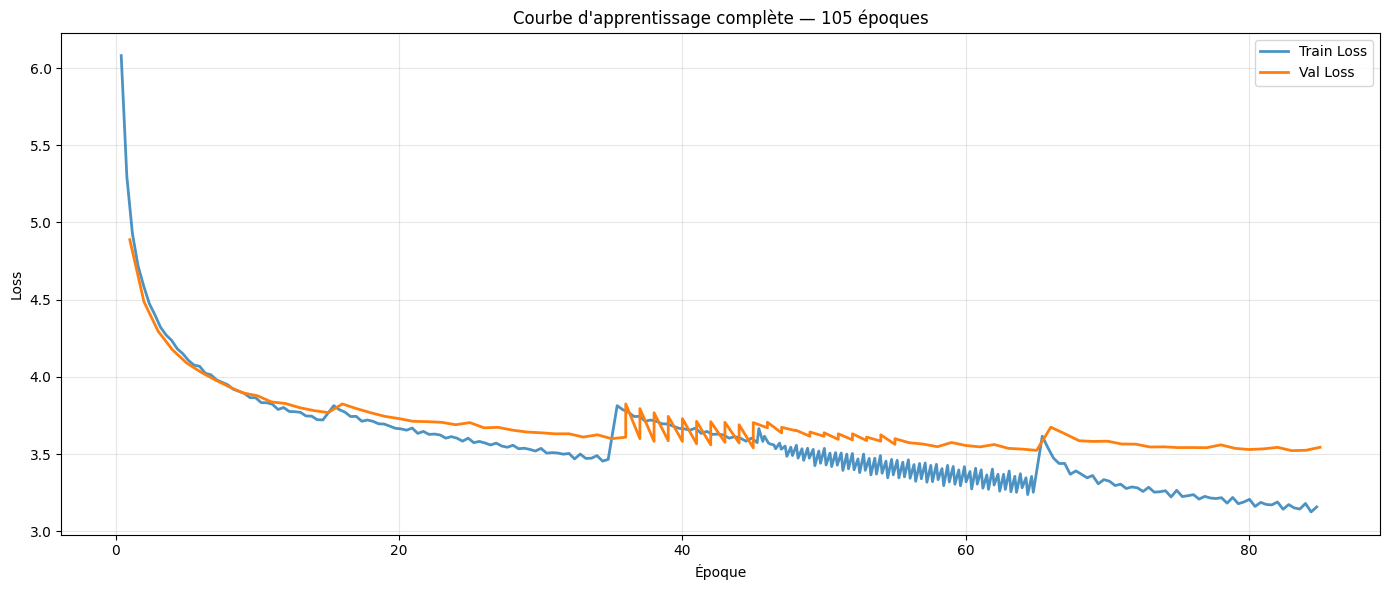


📊 Résumé :
  Époques totales : 105
  Meilleure val loss : 3.5223 (époque 83)
  Dernière val loss  : 3.5439


In [ ]:
# ============================================================
# AFFICHAGE DE LA COURBE COMPLÈTE (depuis le Drive)
# ============================================================
import matplotlib.pyplot as plt

chemin_historique = "/content/drive/MyDrive/Projet_DL/historique_losses.json"

with open(chemin_historique, 'r') as f:
    historique_global = json.load(f)

plt.figure(figsize=(14, 6))
plt.plot(
    historique_global["train_epochs"],
    historique_global["train_loss"],
    label="Train Loss", linewidth=2, alpha=0.8
)
plt.plot(
    historique_global["val_epochs"],
    historique_global["val_loss"],
    label="Val Loss", linewidth=2
)
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title(f"Courbe d'apprentissage complète — {len(historique_global['val_epochs'])} époques")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n📊 Résumé :")
print(f"  Époques totales : {len(historique_global['val_epochs'])}")
print(f"  Meilleure val loss : {min(historique_global['val_loss']):.4f} "
      f"(époque {historique_global['val_epochs'][historique_global['val_loss'].index(min(historique_global['val_loss']))]})")
print(f"  Dernière val loss  : {historique_global['val_loss'][-1]:.4f}")